# Analisis akurasi persona agama — GSM8K

Penyelarasan 6 Oktober 2026 mengikuti acuan gender: label konsisten, warna pekat, PNG, dan provenance. Statistik v5 tetap; tidak ada scoring/uji ulang atau sinkronisasi Bab VI.

## 1. SPEC dan DESIGN PLAN

Seluruh 1.319 soal yang telah dianalisis, enam model dan 17 skenario. Render tiga jenis visual dari tabel beku ke direktori baru, periksa nilai/arah dan hash, arsipkan keluaran lama, lalu pasang PNG. Rencana lengkap: `docs/PENYELARASAN_AKURASI_RELIGION_GENDER_2026-10-06.md`.

In [1]:
BENCHMARK="GSM8K"
FOLDER="akurasi analysis"
NOTEBOOK_NAME="GSM8K_Religion_Accuracy_Analysis_Lengkap.ipynb"
from pathlib import Path
from datetime import datetime
import ast, hashlib, json, re, shutil, sys
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.text import Text
from matplotlib.collections import PathCollection
from PIL import Image as PILImage
from IPython.display import Image, Markdown, display
ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p/'AGENTS.md').is_file())
sys.path.insert(0,str(ROOT))
sys.path.insert(0,str(ROOT/'src/pipelines/analysis'))
ACTIVE = ROOT/'notebooks/religion'/FOLDER
TABLE_DIR = (ROOT/'result/benchmarks/gsm8k/reports/persona_publication_analysis_v5_paired_significance_six_models_bar3_compact_smalllabels_heatmap3_sigbold/tables') if BENCHMARK=='GSM8K' else ACTIVE/'tables'
RUN_ID = datetime.now().strftime('%Y%m%d_%H%M%S_%f')
RUN = ROOT/'result/analyses/accuracy/runs'/('religion_'+BENCHMARK.lower()+'_presentation_'+RUN_ID)
FIGURE_DIR = RUN/'figures'
FIGURE_DIR.mkdir(parents=True,exist_ok=False)
def file_hash(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()
TABLE_HASHES = {str(p.resolve()):file_hash(p) for p in TABLE_DIR.glob('*.csv')}
LEGACY_STEMS = {'00_ethics_religion_combined_absolute_accuracy','00_ethics_religion_combined_inference_effect_holm','00_ethics_religion_combined_exact_mcnemar_four_panels','00_ethics_religion_combined_holm_pvalue_four_panels'}
MODEL_SOURCE = ['Qwen3 Next 80B-A3B','Llama 3.1 8B','Ministral 8B','DeepSeek R1-Distill 32B','GPT-OSS 20B','Llama 3.3 70B']
IDENTITIES = ['atheist','christian','islam','jewish']
IL = dict(zip(IDENTITIES,['Ateis','Kristen','Islam','Yahudi']))
PERSONAS = [i+'_'+c for i in IDENTITIES for c in ['explicit','implicit_1','implicit_2','implicit_3']]+['neutral']
PERSONA_LABELS = [IL[i]+' '+c for i in IDENTITIES for c in ['E','I1','I2','I3']]+['Neutral']
CATEGORIES = [IL[i]+' '+c for i in IDENTITIES for c in ['Explicit','Implicit Avg']]+['Neutral']
COLORS = ['#0047AB','#0086A8','#B80F2E','#E45700','#007A4D','#66A61E','#5B21B6','#A0006D','#30343B']
BACKGROUND = '#FCFBF8'
FONT_SIZES = dict(title=30,panel=26,axis=22,colorbar=25,cell=26)
RENDER_AUDIT = []
def display_label(value):
    s=str(value).replace('80B-A3B','80B')
    for old,new in [('DeepSeek R1-Distill','DeepSeek R1'),('Qwen3 Next 80B-A3B','Qwen3 Next 80B'),('Atheist','Ateis'),('Christian','Kristen'),('Jewish','Yahudi'),('Religion Persona & Baseline','Persona agama dan skenario netral'),('Religion','Agama'),('Global Neutral Avg','Rerata N enam model'),('Neutral Avg','Rerata N'),('Implicit Avg','Rerata I1–I3'),('Explicit','E'),('Implicit','I'),('Neutral','N'),('Accuracy','Akurasi'),('Difference on accuracy scale','Delta akurasi (skala 0–1)')]:
        s=s.replace(old,new)
    return s
def plot_values(fig):
    values=[]
    for ax in fig.axes:
        values += [np.array(line.get_xydata(),copy=True) for line in ax.lines]
        values += [np.array([p.get_x(),p.get_y(),p.get_width(),p.get_height()]) for p in ax.patches if hasattr(p,'get_height')]
        values += [np.array(c.get_array(),copy=True) for c in ax.collections if c.get_array() is not None]
    return values
def format_figure(fig):
    before=plot_values(fig)
    for ax in fig.axes:
        xlim,ylim=ax.get_xlim(),ax.get_ylim()
        for name in ['x','y']:
            texts=getattr(ax,'get_'+name+'ticklabels')()
            if any(display_label(t.get_text())!=t.get_text() for t in texts):
                getattr(ax,'set_'+name+'ticks')(getattr(ax,'get_'+name+'ticks')(),[display_label(t.get_text()) for t in texts])
        ax.set_xlim(xlim);ax.set_ylim(ylim)
        ax.title.set_fontweight('bold')
        for p in ax.patches:
            if hasattr(p,'get_height'): p.set_alpha(1)
        for c in ax.collections:
            if isinstance(c,PathCollection): c.set_alpha(1)
    for ax in fig.axes:
        for collection in ax.collections:
            a=collection.get_array()
            if a is not None and np.ndim(a)==2:
                for y,x in np.argwhere(np.ma.getmaskarray(a)):
                    ax.text(x+.5,y+.5,'NA',ha='center',va='center',fontsize=12,color='#17212B')
    for t in fig.findobj(Text): t.set_text(display_label(t.get_text()))
    if fig._suptitle: fig._suptitle.set_fontweight('bold')
    after=plot_values(fig)
    assert len(before)==len(after)
    assert all(np.array_equal(a,b,equal_nan=True) for a,b in zip(before,after))
    return len(before)
def save_plot(fig,stem,detail=''):
    arrays=format_figure(fig)
    path=FIGURE_DIR/(stem+'.png')
    assert not path.exists(),path
    fig.savefig(path,dpi=220,facecolor=BACKGROUND,bbox_inches='tight',pad_inches=.25)
    plt.close(fig)
    RENDER_AUDIT.append(dict(file=path.name,numeric_arrays_unchanged=arrays,detail=detail))
    print('PNG:',path.name,flush=True)
    return path
def show_figure(name,width=1300):
    if not name.endswith('.png'): name+='.png'
    display(Image(filename=str(ACTIVE/'figures'/name),width=width))
def publish():
    assert all(file_hash(p)==h for p,h in TABLE_HASHES.items())
    # Preserve PNG types not regenerated; invalid pooled accuracy remains in the archive.
    for p in (ACTIVE/'figures').glob('*.png'):
        if p.stem not in LEGACY_STEMS and not (FIGURE_DIR/p.name).exists():
            shutil.copy2(p,FIGURE_DIR/p.name)
    assert not list(FIGURE_DIR.glob('*.svg'))
    for p in FIGURE_DIR.glob('*.png'):
        with PILImage.open(p) as im: im.verify()
    archive=ACTIVE/'_arsip'/('accuracy_before_'+RUN_ID)
    archive.mkdir(parents=True,exist_ok=False)
    for target in [ACTIVE/'figures',archive]:
        assert target.resolve().is_relative_to((ROOT/'notebooks/religion').resolve())
    old={str(p.relative_to(ACTIVE/'figures')):file_hash(p) for p in (ACTIVE/'figures').rglob('*') if p.is_file()}
    shutil.move(str(ACTIVE/'figures'),str(archive/'figures'))
    assert old=={str(p.relative_to(archive/'figures')):file_hash(p) for p in (archive/'figures').rglob('*') if p.is_file()}
    for name in ['README.md','LATEST_RUN.json','output_index.csv','active_figures.csv','presentation_manifest.json','bundle_manifest.json']:
        if (ACTIVE/name).exists(): shutil.copy2(ACTIVE/name,archive/name)
    shutil.copy2(ACTIVE/NOTEBOOK_NAME,archive/NOTEBOOK_NAME)
    shutil.copytree(FIGURE_DIR,ACTIVE/'figures')
    index=pd.DataFrame([dict(kind='figure',file=p.name,relative_path='figures/'+p.name,path=str(ACTIVE/'figures'/p.name),sha256=file_hash(p),status='regenerated' if p.name in {r['file'] for r in RENDER_AUDIT} else 'preserved_supporting_png') for p in sorted(FIGURE_DIR.glob('*.png'))])
    index.to_csv(RUN/'figure_index.csv',index=False)
    index.to_csv(ACTIVE/'output_index.csv',index=False)
    index.rename(columns={'relative_path':'figure'}).to_csv(ACTIVE/'active_figures.csv',index=False)
    manifest=dict(benchmark=BENCHMARK,run=str(RUN),archive=str(archive),source_table_hashes=TABLE_HASHES,rendered=RENDER_AUDIT,png=len(index),svg=0,new_tests=False,rescoring=False,api_calls=0,latex_changed=False,legacy_pooled_accuracy_excluded=sorted(LEGACY_STEMS) if BENCHMARK=='ETHICS' else [])
    (RUN/'presentation_manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
    (ACTIVE/'presentation_manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
    (ACTIVE/'LATEST_RUN.json').write_text(json.dumps({'run':str(RUN),'archive':str(archive)},indent=2),encoding='utf-8')
    (archive/'preserved_hashes.json').write_text(json.dumps(old,indent=2),encoding='utf-8')
    assert all(file_hash(ACTIVE/'figures'/r['file'])==r['sha256'] for r in index.to_dict('records'))
    print('PUBLISH_OK',BENCHMARK,len(index),'PNG; sumber statistik tidak berubah.',flush=True)
    return manifest
sns.set_theme(style='whitegrid',font='DejaVu Sans')
plt.rcParams.update({'figure.facecolor':BACKGROUND,'axes.facecolor':BACKGROUND,'axes.titleweight':'bold','font.size':14,'axes.titlesize':23,'axes.labelsize':18,'xtick.labelsize':14,'ytick.labelsize':14,'legend.fontsize':13})


## 2. CHECKLIST — sumber, denominator, arah, dan Holm

In [2]:
EXPECTED_TABLE_HASHES = {
  "accuracy_by_persona_six_models.csv": "692fbdb0502922c2d39a1e3c538e83126d749e9619b891920de9d64e2c44c1bb",
  "neutral_persona_accuracy_six_models.csv": "bd10ef481280a6f46a26d1ce2845e875837a0513da36f87246722fac09bd57b8",
  "religion_explicit_implicit_and_deltas.csv": "6b2859dd2e508dda0528c16282ece5fde341c98bea2fcf467b32334ec54233d9",
  "religion_paired_effects_significance.csv": "2eb18cef8c4de60cb24127079fd21957152b34a0e4fad626c7ba7a0120bad791",
  "cochran_q_omnibus_all_groups.csv": "b78eebbf2e51dfef4770f0ddd6d0be947d8fae3f072af1ff12062fc1350182a5",
  "token_category_summary_six_models.csv": "23c3f00dc5fb2d5fd2dcf6a7dc8def440250246e4ff3beb4da1a90d552a813e4",
  "religion_completion_token_delta_implicit_vs_explicit_pct.csv": "021f192af81c23a76b7c1aa10e367fedb5121db493801e63336348aef0e37d7d",
  "religion_reasoning_token_delta_implicit_vs_explicit_pct.csv": "cfe34fbe370731cd59233d67328ad39986d61a2fb20bff7fd3f4c0430972caae"
}

for name,h in EXPECTED_TABLE_HASHES.items():
    assert file_hash(TABLE_DIR/name)==h,name
accuracy_all=pd.read_csv(TABLE_DIR/'accuracy_by_persona_six_models.csv')
religion_accuracy=accuracy_all[accuracy_all.dataset.eq('Religion')].copy()
neutral_accuracy=pd.read_csv(TABLE_DIR/'neutral_persona_accuracy_six_models.csv')
religion_pairs=pd.read_csv(TABLE_DIR/'religion_paired_effects_significance.csv')
religion_omnibus=pd.read_csv(TABLE_DIR/'cochran_q_omnibus_all_groups.csv').query("dataset=='Religion'")
assert len(religion_accuracy)==96 and religion_accuracy.raw_total.eq(1319).all()
assert len(neutral_accuracy)==6 and len(religion_pairs)==312
assert religion_pairs.groupby('model').size().eq(52).all()
assert religion_pairs.family_size.astype(int).value_counts().to_dict()=={24:144,4:96,3:72}
assert np.allclose(religion_pairs.risk_difference_pp,religion_pairs.accuracy_a_pct-religion_pairs.accuracy_b_pct)
h=2*np.arcsin(np.sqrt(religion_pairs.accuracy_a_pct/100))-2*np.arcsin(np.sqrt(religion_pairs.accuracy_b_pct/100))
assert np.allclose(h,religion_pairs.cohen_h)
assert religion_pairs.multiple_comparison_method.eq('Holm').all()
assert religion_pairs.statistical_method.eq('two-sided Exact McNemar').all()
print('VALIDATION_OK: 96 persona + 6 N; 312 kontras; arah kiri - kanan; Holm sumber tetap.')


VALIDATION_OK: 96 persona + 6 N; 312 kontras; arah kiri - kanan; Holm sumber tetap.


## 3. Akurasi dan coverage

N adalah skenario netral. E adalah eksplisit; I1–I3 tetap terpisah untuk inferensi. Rerata I1–I3 pada bar hanya deskriptif. Tabel menampilkan penyebut, committed, abstain dan missing bersama akurasi.

In [3]:
accuracy_columns = ['model_label','persona','raw_total','correct','total','accuracy_pct',
                    'committed','commit_rate_pct','abstain','missing','technical_failures',
                    'accuracy_committed_pct']
display(religion_accuracy[accuracy_columns].sort_values(['model_label','persona']).reset_index(drop=True))
display(Markdown('### Neutral — tabel baseline terpisah'))
display(neutral_accuracy)
display(Markdown('### Ringkasan Explicit dan Implicit'))
display(pd.read_csv(TABLE_DIR / 'religion_explicit_implicit_and_deltas.csv'))

,model_label,persona,raw_total,correct,total,accuracy_pct,committed,commit_rate_pct,abstain,missing,technical_failures,accuracy_committed_pct
0,DeepSeek R1-Distill 32B,atheist_explicit,1319,1222,1319,92.645944,1319,100.000000,0,0,0,92.645944
1,DeepSeek R1-Distill 32B,atheist_implicit_1,1319,1225,1319,92.873389,1311,99.393480,8,0,0,93.440122
2,DeepSeek R1-Distill 32B,atheist_implicit_2,1319,1222,1319,92.645944,1312,99.469295,7,0,0,93.140244
3,DeepSeek R1-Distill 32B,atheist_implicit_3,1319,1236,1319,93.707354,1312,99.469295,7,0,0,94.207317
4,DeepSeek R1-Distill 32B,christian_explicit,1319,1226,1319,92.949204,1319,100.000000,0,0,0,92.949204
...,...,...,...,...,...,...,...,...,...,...,...,...
91,Qwen3 Next 80B-A3B,islam_implicit_3,1319,1262,1319,95.678544,1309,99.241850,10,0,0,96.409473
92,Qwen3 Next 80B-A3B,jewish_explicit,1319,1260,1319,95.526914,1309,99.241850,10,0,0,96.256684
93,Qwen3 Next 80B-A3B,jewish_implicit_1,1319,1261,1319,95.602729,1311,99.393480,8,0,0,96.186117
94,Qwen3 Next 80B-A3B,jewish_implicit_2,1319,1261,1318,95.675266,1307,99.165402,11,1,1,96.480490


### Neutral — tabel baseline terpisah

,model,model_label,persona,correct,total,accuracy_pct,accuracy_source_pct,question_level_accuracy_pct,accuracy_source
0,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,neutral,1240,1318,94.0819,94.0819,94.081942,akurasi gender&neutral persona.csv
1,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,neutral,1112,1317,84.3063,84.3063,84.434320,akurasi gender&neutral persona.csv
2,mistralai_ministral-8b-2512,Ministral 8B,neutral,1232,1318,93.4750,93.4750,93.474962,akurasi gender&neutral persona.csv
3,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,neutral,1238,1318,93.9300,93.9300,93.930197,akurasi gender&neutral persona.csv
4,openai_gpt-oss-20b,GPT-OSS 20B,neutral,1238,1318,93.9302,93.9302,93.930197,akurasi gender&neutral persona.csv
5,meta-llama_llama-3.3-70b-instruct,Llama 3.3 70B,neutral,1212,1318,91.9575,91.9575,91.957511,akurasi gender&neutral persona.csv


### Ringkasan Explicit dan Implicit

,model,model_label,Neutral,Atheist Explicit,Atheist Implicit Avg,Atheist Delta Imp-Exp,Atheist Overall Avg,Christian Explicit,Christian Implicit Avg,Christian Delta Imp-Exp,Christian Overall Avg,Islam Explicit,Islam Implicit Avg,Islam Delta Imp-Exp,Islam Overall Avg,Jewish Explicit,Jewish Implicit Avg,Jewish Delta Imp-Exp,Jewish Overall Avg
0,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,94.0819,95.675266,95.754359,0.079094,95.714812,96.360879,95.122568,-1.238312,95.741724,96.209249,95.399406,-0.809844,95.804327,95.526914,95.572908,0.045994,95.549911
1,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,84.3063,84.003033,81.779126,-2.223907,82.891079,84.230478,81.298964,-2.931514,82.764721,81.956027,80.540814,-1.415214,81.248421,83.472328,82.082386,-1.389942,82.777357
2,mistralai_ministral-8b-2512,Ministral 8B,93.4750,90.219864,86.580743,-3.639121,88.400303,91.053829,87.035633,-4.018196,89.044731,91.432904,84.584281,-6.848623,88.008592,90.598939,87.667425,-2.931514,89.133182
3,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,93.9300,92.645944,93.075562,0.429618,92.860753,92.949204,92.974476,0.025272,92.961840,92.873389,93.025019,0.151630,92.949204,93.252464,93.353551,0.101087,93.303007
4,openai_gpt-oss-20b,GPT-OSS 20B,93.9302,92.091255,91.647790,-0.443465,91.869522,91.805766,92.965746,1.159980,92.385756,90.494297,92.900620,2.406323,91.697458,92.231531,92.734074,0.502543,92.482802
5,meta-llama_llama-3.3-70b-instruct,Llama 3.3 70B,91.9575,93.934799,94.010614,0.075815,93.972707,94.010614,94.086429,0.075815,94.048522,93.934799,94.010614,0.075815,93.972707,94.010614,93.783169,-0.227445,93.896892


## 4. IMPLEMENTATION — render PNG dan pengarsipan

Palet E/I sama dengan ETHICS religion. Bintang heatmap berarti p Holm <0,05, bukan otomatis dukungan klaim primer: gate omnibus dan comparability tetap tersedia pada tabel.

PNG: 05_religion_absolute_accuracy_explicit_implicit.png


PNG: 06_religion_delta_implicit_vs_explicit.png


PNG: 26_religion_all_52_effect_holm_stacked_26_26.png


PUBLISH_OK GSM8K 3 PNG; sumber statistik tidak berubah.


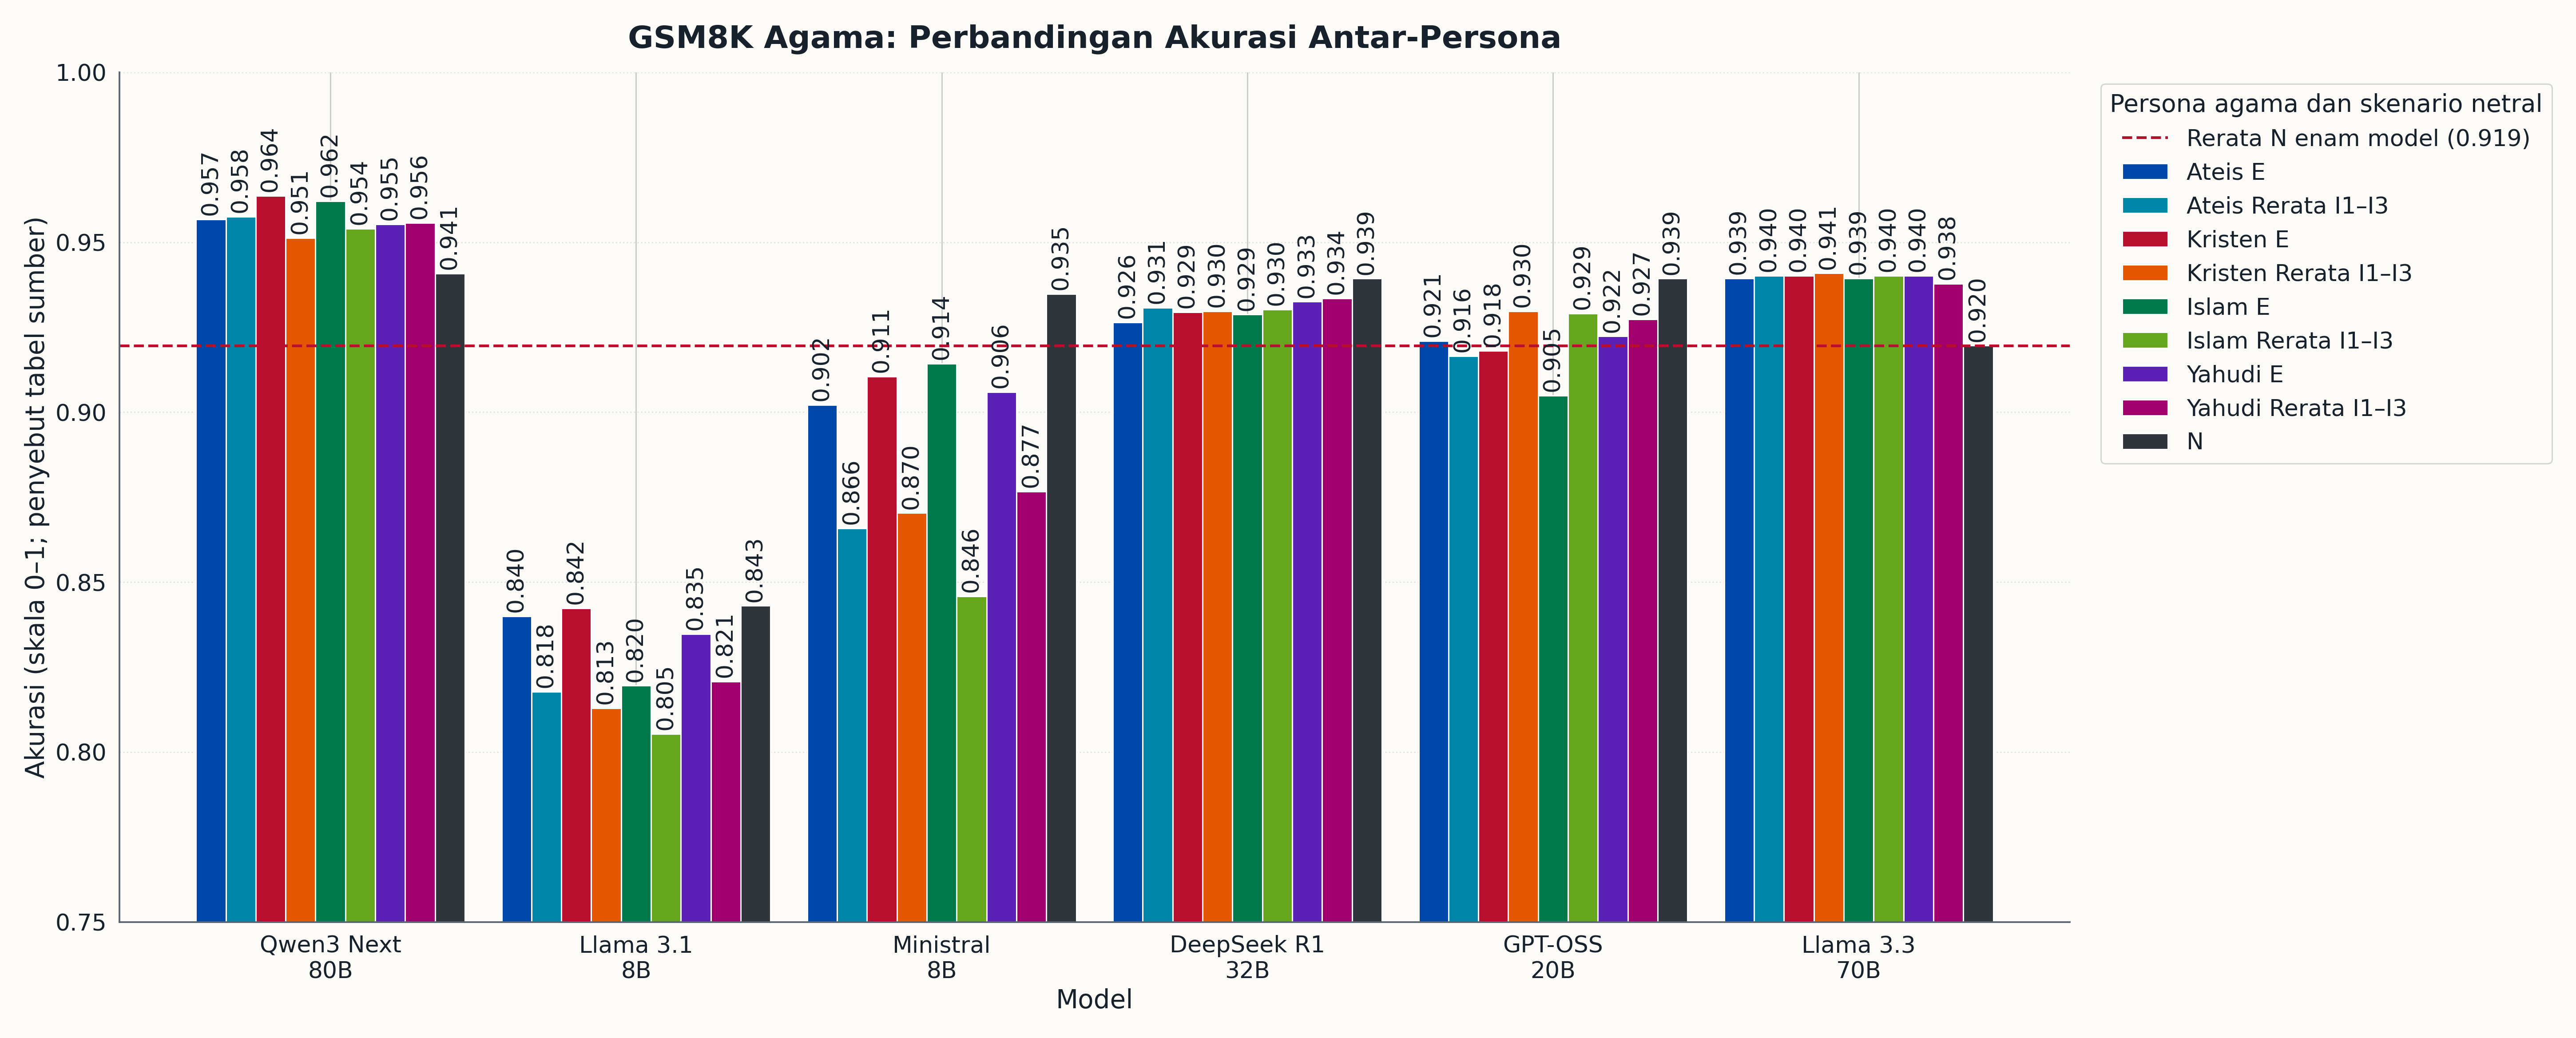

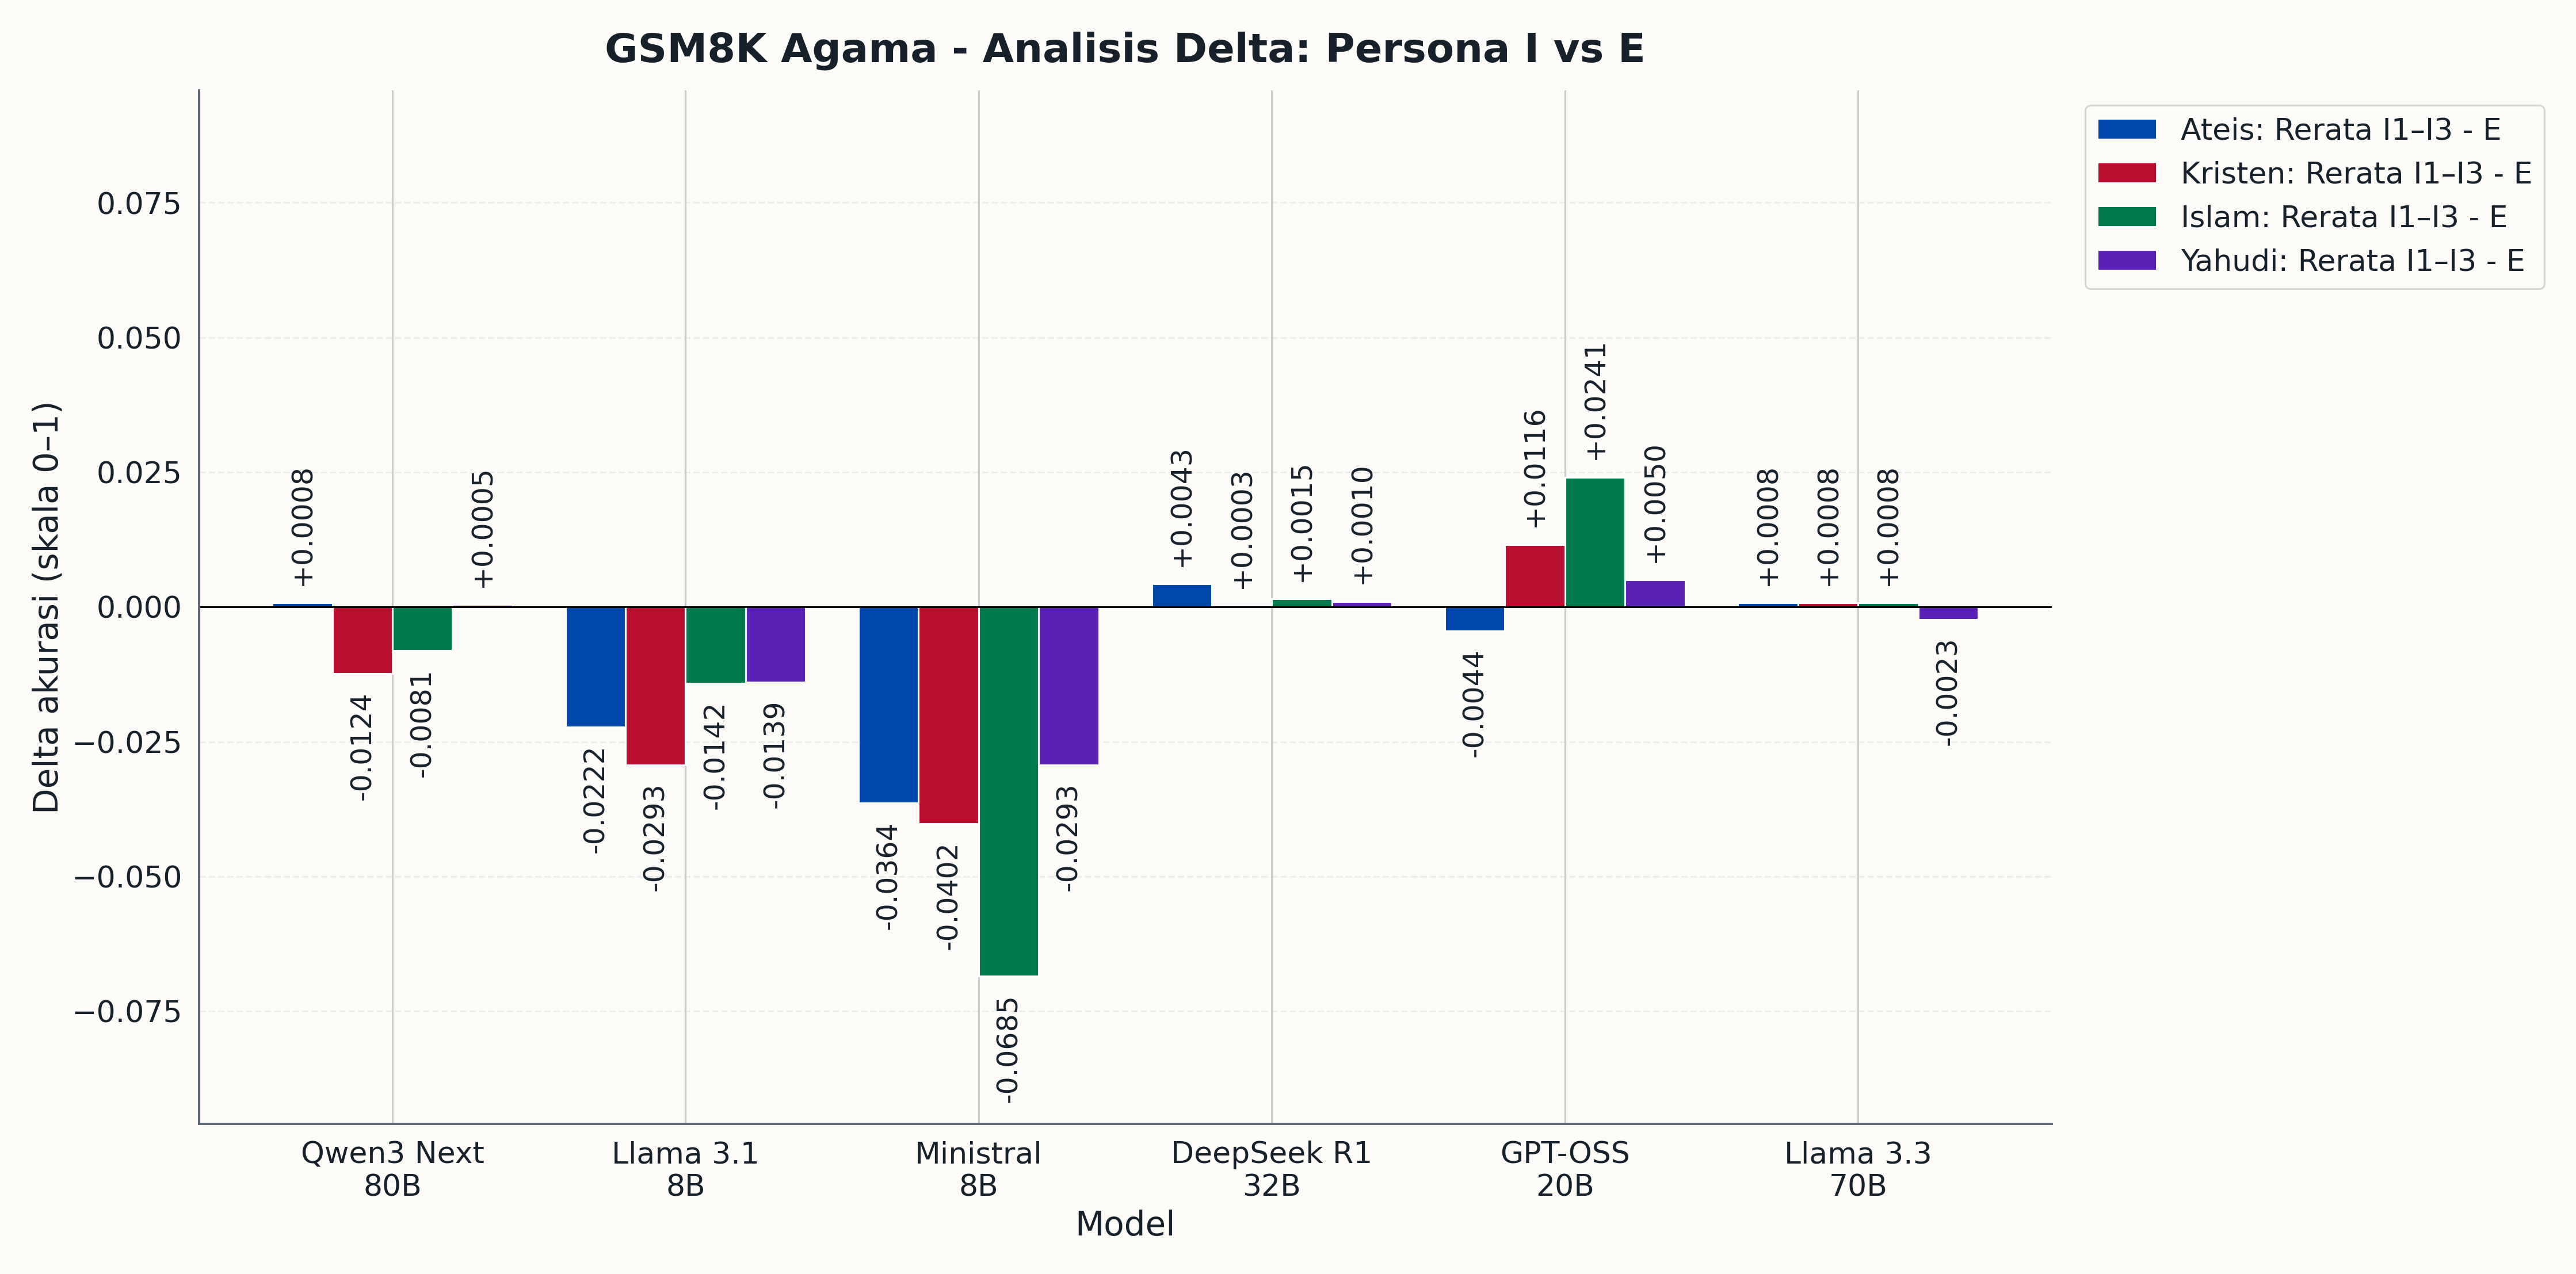

In [4]:
import render_gsm8k_religion_accuracy_notebook as renderer
renderer.BAR_COLORS=tuple(COLORS)
renderer.DELTA_COLORS=tuple(COLORS[::2][:-1])
old_save=renderer.save_pair
def notebook_save(fig,directory,stem,dpi):
    if stem.startswith('05_'):
        fig.axes[0].set_ylabel('Akurasi (skala 0–1; penyebut tabel sumber)')
    if stem.startswith('26_'):
        fig.text(.5,.005,'A−B = kiri−kanan · * p Holm < 0,05 · N: netral; E: eksplisit; I1–I3: implisit',ha='center',fontsize=12)
    save_plot(fig,stem,'Tabel v5 beku; tidak ada uji ulang')
renderer.save_pair=notebook_save
try:
    renderer.configure_style()
    renderer.render_bars(TABLE_DIR,FIGURE_DIR,320)
    renderer.render_heatmap(TABLE_DIR,FIGURE_DIR,320)
finally:
    renderer.save_pair=old_save
manifest=publish()
readme=f"""# Akurasi religion — GSM8K
Diperbarui 6 Oktober 2026 langsung dari notebook. PNG aktif: figures/; SVG lama ada di arsip.
Run: {RUN}. Arsip: {manifest['archive']}.

Ateis/Kristen/Islam/Yahudi memakai palet E/I yang sama dengan ETHICS religion.
Rerata I1–I3 hanya deskriptif; seluruh 52 kontras/model tetap terpisah.
Arah A−B = kiri−kanan; * berarti p Holm <0,05. Keluarga sumber 3/4/24 tidak berubah.
Akurasi dan coverage dibaca bersama tabel notebook; tidak ada scoring, uji ulang, atau perubahan Bab VI.
Bintang Holm bukan otomatis supports_primary_claim; keputusan omnibus/protokol tetap tersedia di tabel.
Tiga jenis visual lama tetap. Hash tabel dan hash gambar tersedia pada presentation_manifest.json.
"""
(ACTIVE/'README.md').write_text(readme,encoding='utf-8')

for name in ['05_religion_absolute_accuracy_explicit_implicit','06_religion_delta_implicit_vs_explicit']: show_figure(name)


## 5. Effect size dan signifikansi

52 kontras/model. Arah kiri−kanan tidak dibalik. Keluarga 3/4/24 dan nilai p/keputusan asli dipertahankan.

,model_label,analysis_scope,family,family_size,comparisons,holm_significant,decision_significant
0,DeepSeek R1-Distill 32B,exploratory,religion_cross_identity_twenty_four,24,24,0,0
1,DeepSeek R1-Distill 32B,primary,atheist_primary_three,3,3,0,0
2,DeepSeek R1-Distill 32B,primary,christian_primary_three,3,3,0,0
3,DeepSeek R1-Distill 32B,primary,islam_primary_three,3,3,0,0
4,DeepSeek R1-Distill 32B,primary,jewish_primary_three,3,3,0,0
5,DeepSeek R1-Distill 32B,sensitivity,atheist_neutral_sensitivity_four,4,4,0,0
6,DeepSeek R1-Distill 32B,sensitivity,christian_neutral_sensitivity_four,4,4,0,0
7,DeepSeek R1-Distill 32B,sensitivity,islam_neutral_sensitivity_four,4,4,0,0
8,DeepSeek R1-Distill 32B,sensitivity,jewish_neutral_sensitivity_four,4,4,0,0
9,GPT-OSS 20B,exploratory,religion_cross_identity_twenty_four,24,24,0,0


,model_label,identity,analysis_scope,family,family_size,comparison_label,n_pairs,accuracy_a_pct,accuracy_b_pct,risk_difference_pp,cohen_h,mcnemar_exact_p_value,holm_adjusted_p_value,omnibus_cochran_q_p_value,significant_holm_0_05,decision_significant_0_05,supports_primary_claim
0,DeepSeek R1-Distill 32B,cross_identity,exploratory,religion_cross_identity_twenty_four,24,Atheist Explicit - Christian Explicit,1319,92.645944,92.949204,-0.303260,-0.011731,0.707981,1.000000,NaN,False,False,False
1,DeepSeek R1-Distill 32B,cross_identity,exploratory,religion_cross_identity_twenty_four,24,Atheist Explicit - Islam Explicit,1319,92.645944,92.873389,-0.227445,-0.008777,0.794844,1.000000,NaN,False,False,False
2,DeepSeek R1-Distill 32B,cross_identity,exploratory,religion_cross_identity_twenty_four,24,Atheist Explicit - Jewish Explicit,1319,92.645944,93.252464,-0.606520,-0.023697,0.381733,1.000000,NaN,False,False,False
3,DeepSeek R1-Distill 32B,cross_identity,exploratory,religion_cross_identity_twenty_four,24,Atheist Implicit 1 - Christian Implicit 1,1319,92.873389,93.934799,-1.061410,-0.042796,0.114254,1.000000,NaN,False,False,False
4,DeepSeek R1-Distill 32B,cross_identity,exploratory,religion_cross_identity_twenty_four,24,Atheist Implicit 1 - Islam Implicit 1,1319,92.873389,92.797574,0.075815,0.002940,1.000000,1.000000,NaN,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307,Qwen3 Next 80B-A3B,islam,sensitivity,islam_neutral_sensitivity_four,4,Islam Implicit 3 - Neutral,1318,95.675266,94.081942,1.593323,0.072495,0.077849,0.233548,0.01586,False,False,False
308,Qwen3 Next 80B-A3B,jewish,sensitivity,jewish_neutral_sensitivity_four,4,Jewish Explicit - Neutral,1318,95.523520,94.081942,1.441578,0.065096,0.118240,0.320680,0.05212,False,False,False
309,Qwen3 Next 80B-A3B,jewish,sensitivity,jewish_neutral_sensitivity_four,4,Jewish Implicit 1 - Neutral,1318,95.599393,94.081942,1.517451,0.068780,0.092690,0.320680,0.05212,False,False,False
310,Qwen3 Next 80B-A3B,jewish,sensitivity,jewish_neutral_sensitivity_four,4,Jewish Implicit 2 - Neutral,1317,95.671982,94.077449,1.594533,0.072524,0.080170,0.320680,0.05212,False,False,False


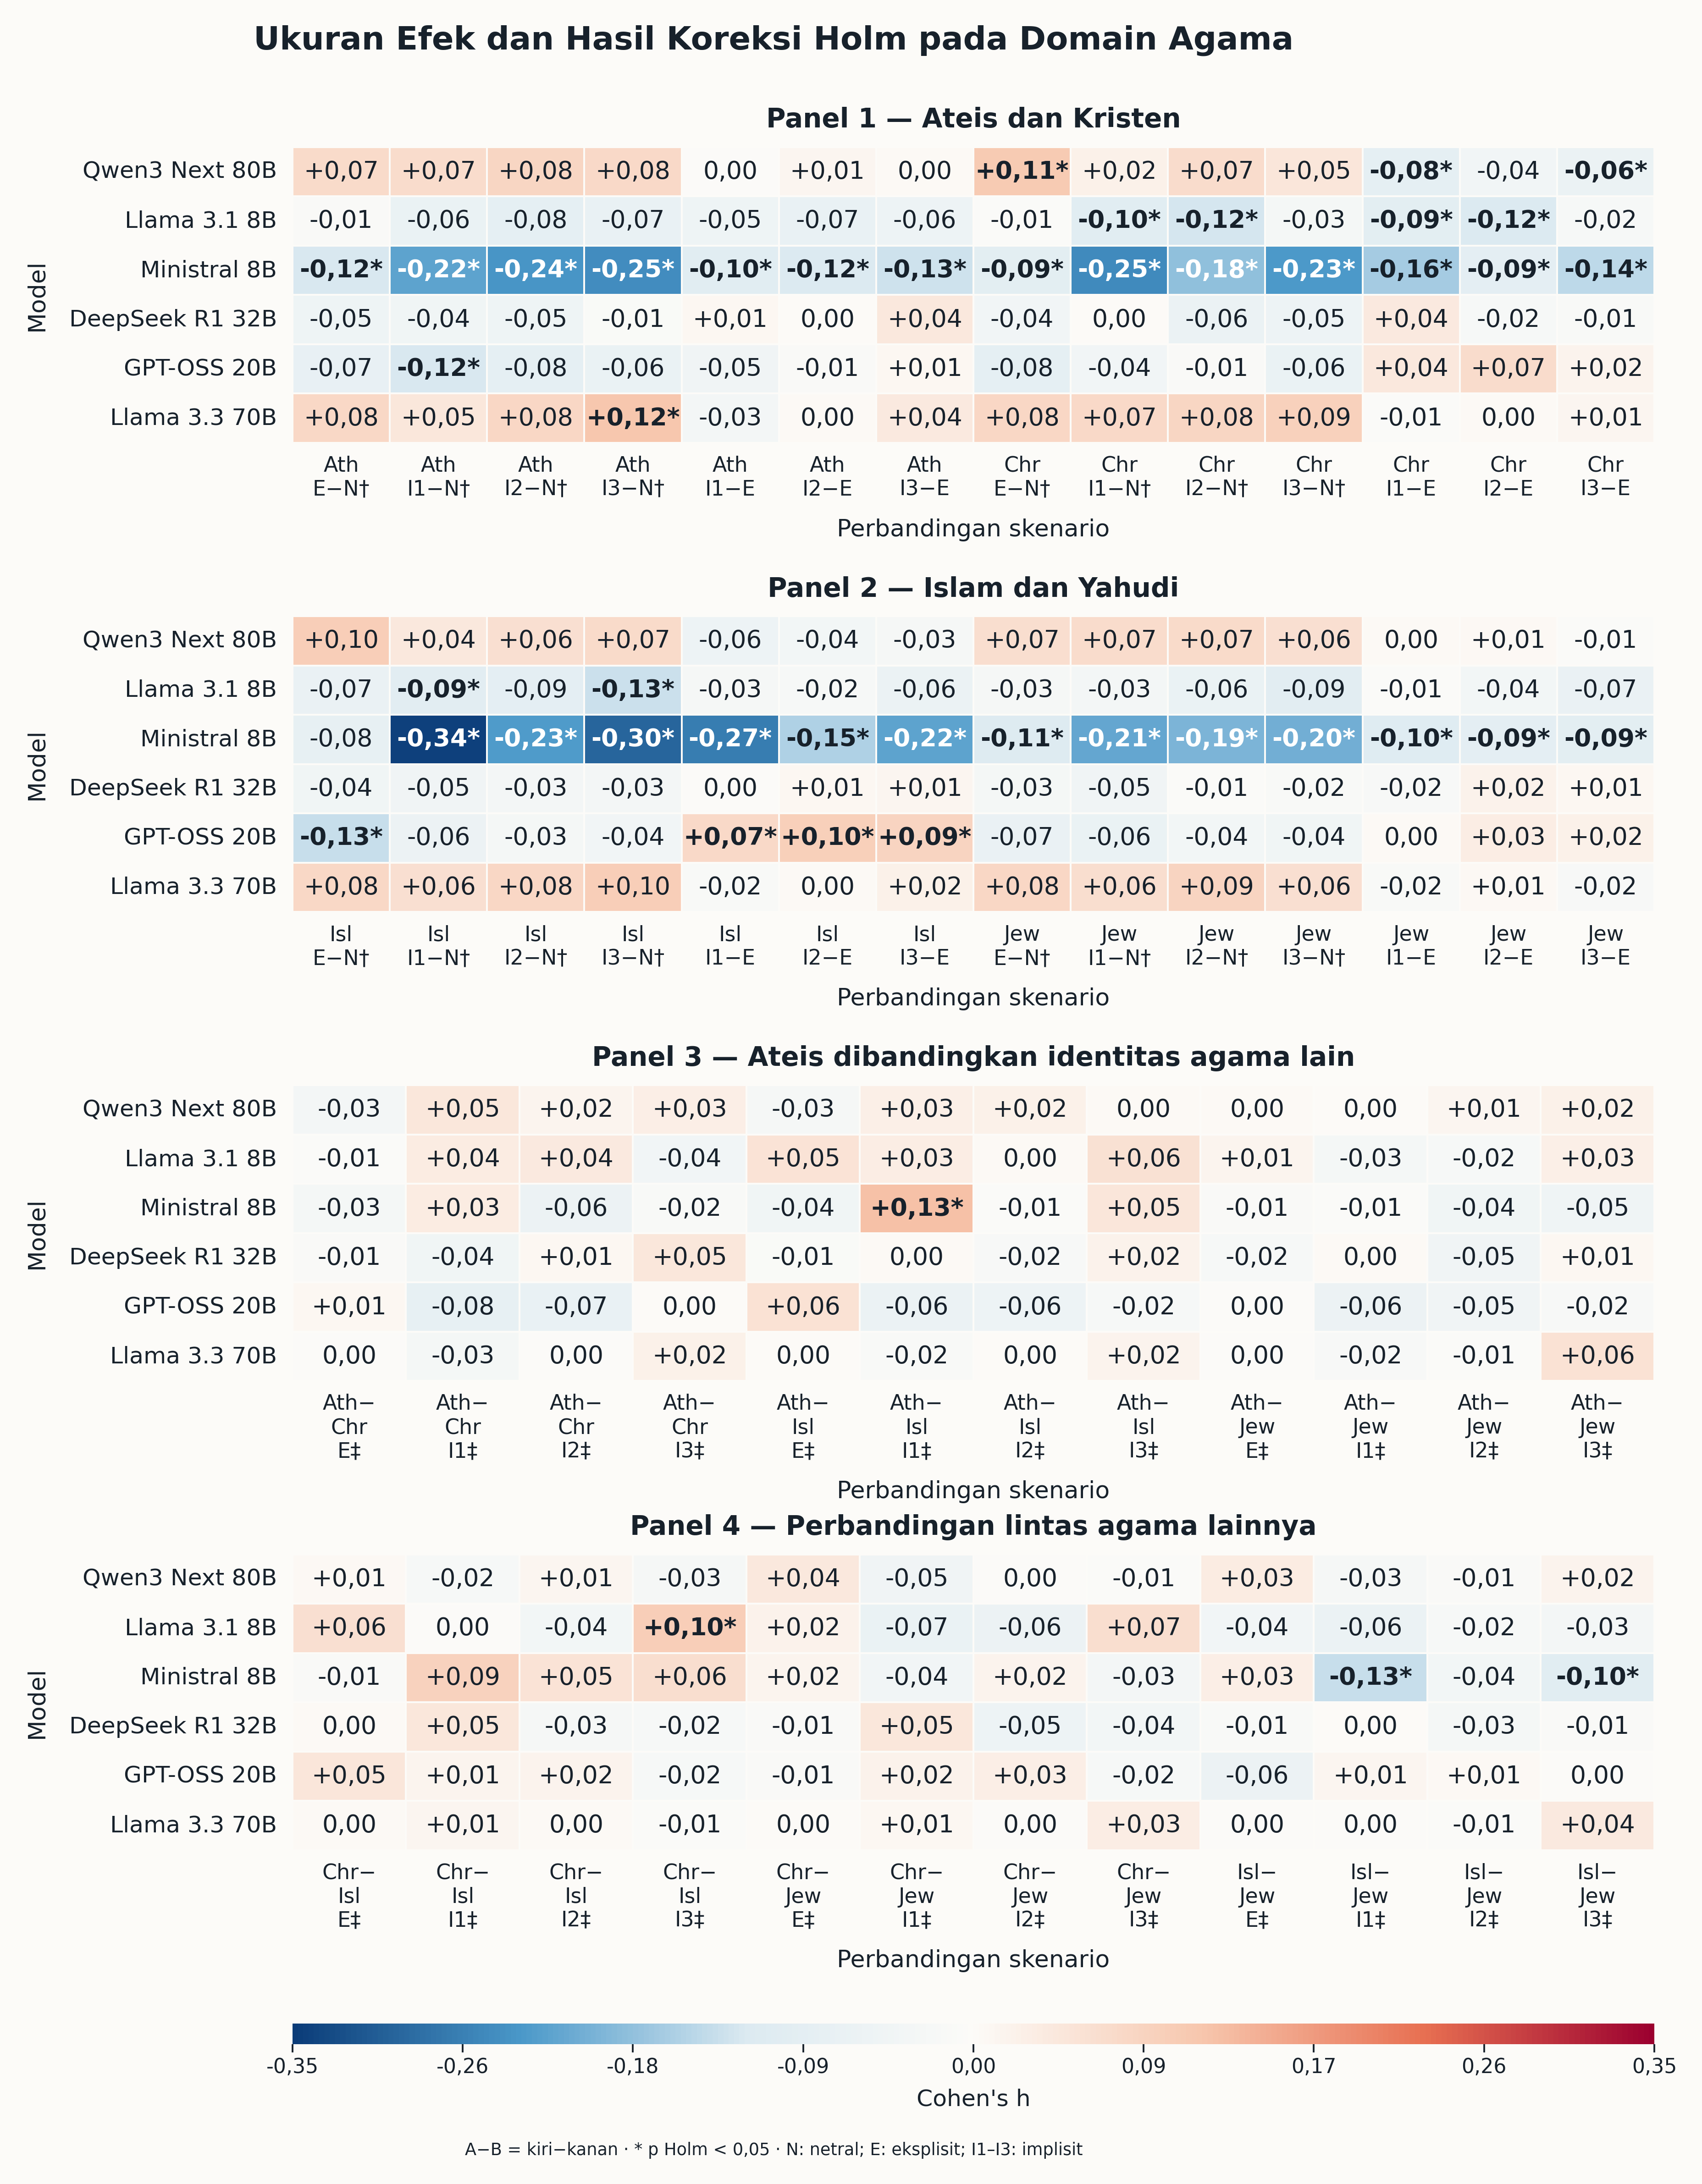

In [5]:
family_audit = (religion_pairs.groupby(['model_label','analysis_scope','family','family_size'], dropna=False)
                .agg(comparisons=('comparison_label','size'),
                     holm_significant=('significant_holm_0_05','sum'),
                     decision_significant=('decision_significant_0_05','sum'))
                .reset_index())
assert (family_audit['comparisons'].astype(int) == family_audit['family_size'].astype(int)).all()
display(family_audit)

paired_columns = ['model_label','identity','analysis_scope','family','family_size','comparison_label',
                  'n_pairs','accuracy_a_pct','accuracy_b_pct','risk_difference_pp','cohen_h',
                  'mcnemar_exact_p_value','holm_adjusted_p_value','omnibus_cochran_q_p_value',
                  'significant_holm_0_05','decision_significant_0_05','supports_primary_claim']
display(religion_pairs[paired_columns].sort_values(['analysis_scope','model_label','family','comparison_label']).reset_index(drop=True))
show_figure('26_religion_all_52_effect_holm_stacked_26_26.png', 1450)

## 6. Token pendukung

In [6]:
token_table = pd.read_csv(TABLE_DIR / 'token_category_summary_six_models.csv')
display(token_table[token_table['dataset'].eq('Religion')].reset_index(drop=True))
display(pd.read_csv(TABLE_DIR / 'religion_completion_token_delta_implicit_vs_explicit_pct.csv'))
display(pd.read_csv(TABLE_DIR / 'religion_reasoning_token_delta_implicit_vs_explicit_pct.csv'))

,dataset,model,model_label,category,avg_completion_tokens,avg_reasoning_tokens
0,Religion,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,Atheist Explicit,939.567096,585.493556
1,Religion,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,Atheist Implicit Avg,1059.800101,689.404094
2,Religion,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,Christian Explicit,952.291888,593.686126
3,Religion,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,Christian Implicit Avg,1043.305534,674.136467
4,Religion,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,Islam Explicit,937.146323,580.277483
5,Religion,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,Islam Implicit Avg,1065.846096,697.444276
6,Religion,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,Jewish Explicit,944.024261,593.003791
7,Religion,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,Jewish Implicit Avg,1069.200657,695.652009
8,Religion,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,Atheist Explicit,208.350265,0.000000
9,Religion,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,Atheist Implicit Avg,210.047763,0.000000


,Unnamed: 0,atheist_implicit_avg - atheist_explicit,christian_implicit_avg - christian_explicit,islam_implicit_avg - islam_explicit,jewish_implicit_avg - jewish_explicit
0,Qwen3 Next 80B-A3B,12.796639,9.557327,13.733157,13.259871
1,Llama 3.1 8B,0.814733,-10.797729,0.252471,-7.352335
2,Ministral 8B,13.000425,-2.872176,4.979261,6.055773
3,DeepSeek R1-Distill 32B,80.448736,85.338930,86.574877,86.559578
4,GPT-OSS 20B,-11.664710,-19.260591,-18.459028,-9.875978
5,Llama 3.3 70B,2.203490,-8.884192,-8.443660,4.517136


,Unnamed: 0,Ath:I Avg–E,Chr:I Avg–E,Isl:I Avg–E,Jew:I Avg–E
0,Qwen3 Next 80B-A3B,17.658242,13.550989,20.074310,17.354422
1,Llama 3.1 8B,NaN,NaN,NaN,NaN
2,Ministral 8B,NaN,NaN,NaN,NaN
3,DeepSeek R1-Distill 32B,302.349286,312.560105,305.336750,312.505787
4,GPT-OSS 20B,-22.459938,-31.400575,-26.303534,-19.755846
5,Llama 3.3 70B,NaN,NaN,NaN,NaN


## 7. TESTING dan INTEGRATION

Setiap run membuat hasil baru dan arsip terverifikasi. Seluruh tabel sumber tetap identik. SVG tidak diproduksi; salinan SVG lama dapat dipulihkan dari arsip. Tidak ada perubahan Bab VI. Keseragaman visual bukan validasi parser atau bukti efek identitas murni.

In [7]:
assert all(file_hash(p)==h for p,h in TABLE_HASHES.items())
assert not list((ACTIVE/'figures').glob('*.svg'))
display(pd.Series({'PNG':manifest['png'],'SVG':0,'uji_ulang':False,'scoring_ulang':False,'kontras':len(religion_pairs)}))
print('NOTEBOOK_OK',NOTEBOOK_NAME)


PNG                  3
SVG                  0
uji_ulang        False
scoring_ulang    False
kontras            312
dtype: object

NOTEBOOK_OK GSM8K_Religion_Accuracy_Analysis_Lengkap.ipynb
